# DumGPT 124M


In [1]:
# Install notebook dependencies into the active Jupyter kernel.
%pip install -q tiktoken datasets huggingface_hub tqdm matplotlib pandas

import torch
print("=" * 64)
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"BF16 supported  : {torch.cuda.is_bf16_supported()}")
    props = torch.cuda.get_device_properties(0)
    print(f"VRAM            : {props.total_memory / (1024**3):.2f} GB")
else:
    print("Running on CPU. Training a 124M model on CPU will be very slow.")
print("=" * 64)


Note: you may need to restart the kernel to use updated packages.
PyTorch version : 2.7.0+cu126
CUDA available  : True
GPU             : NVIDIA RTX 5000 Ada Generation
BF16 supported  : True
VRAM            : 31.48 GB


In [2]:
import os

# Use official Hugging Face Hub
os.environ["HF_ENDPOINT"] = "https://huggingface.co"

# Remove any stale token overrides
os.environ.pop("HF_TOKEN", None)
os.environ.pop("HUGGING_FACE_HUB_TOKEN", None)

print("HF endpoint:", os.environ["HF_ENDPOINT"])

HF endpoint: https://huggingface.co


In [3]:
import huggingface_hub

from huggingface_hub import constants

print("Configured endpoint:", constants.ENDPOINT)

Configured endpoint: https://huggingface.co


/home/kmpooja/.local/lib/python3.10/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


In [4]:
from huggingface_hub import login, whoami

login(skip_if_logged_in=False)

print("Authenticated:", whoami()["name"])

Authenticated: shubhamisok


## Step 2: Local configuration

The defaults below are intentionally conservative for a laptop GPU with around 4 GB VRAM. If you have more VRAM, increase `B` first, then consider increasing `T`.

`MAX_TOKENS_TO_PREPARE` controls how much FineWeb-Edu data is downloaded and tokenized. The default is a small starter subset, **not** the full 10BT dataset.


In [5]:
from dataclasses import dataclass
from pathlib import Path
import os
import torch

# --- LOCAL STORAGE ---
# All generated files stay in this folder beside the notebook.
BASE_DIR = Path.cwd() / "DumGPT"
DATA_DIR = BASE_DIR / "edu_fineweb"
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
OUTPUT_DIR = BASE_DIR / "outputs"
HELLASWAG_CACHE_DIR = BASE_DIR / "hellaswag"

for directory in (DATA_DIR, CHECKPOINT_DIR, OUTPUT_DIR, HELLASWAG_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# --- MODEL ARCHITECTURE: GPT-2 124M ---
BLOCK_SIZE = 1024
VOCAB_SIZE = 50304
N_LAYER = 12
N_HEAD = 12
N_EMBD = 768

@dataclass
class GPTConfig:
    block_size: int = BLOCK_SIZE
    vocab_size: int = VOCAB_SIZE
    n_layer: int = N_LAYER
    n_head: int = N_HEAD
    n_embd: int = N_EMBD

# --- LOCAL GPU SETTINGS ---
# For ~4 GB VRAM: start with B=1, T=256.
# For 6-8 GB: try B=1 or 2, T=1024.
# For 12+ GB: try B=2 or 4, T=1024.
B = 1
T = 256
TOTAL_BATCH_SIZE = 4096  # Effective tokens/update; must divide evenly by B*T.

MAX_LR = 6e-4
MIN_LR = MAX_LR * 0.1
WARMUP_STEPS = 50
MAX_STEPS = 1000
WEIGHT_DECAY = 0.1

# --- EVALUATION / CHECKPOINTING ---
VAL_INTERVAL = 100
VAL_STEPS = 5
HELLASWAG_INTERVAL = 0       # Set to e.g. 250 to enable; adds evaluation time.
HELLASWAG_MAX_EXAMPLES = 100
SAVE_INTERVAL = 100
SAMPLE_INTERVAL = 250
USE_GRADIENT_CHECKPOINTING = True

# --- DATA PREPARATION ---
SHARD_SIZE = 100_000_000        # tokens per shard; uint16 uses ~10 MB per 5M tokens
MAX_TOKENS_TO_PREPARE = None  # starter subset; set None only if you have ample disk/time
VAL_TOKENS = 1_000_000        # first tokens reserved for validation

print(f"Project directory : {BASE_DIR}")
print(f"Device             : {'CUDA' if torch.cuda.is_available() else 'CPU'}")
print(f"Micro-batch        : B={B}, T={T}")
print(f"Gradient steps     : {TOTAL_BATCH_SIZE // (B*T)}")
print(f"Token preparation  : {MAX_TOKENS_TO_PREPARE:,}" if MAX_TOKENS_TO_PREPARE else "Token preparation: unlimited")


Project directory : /DATA/tt/DumGPT
Device             : CUDA
Micro-batch        : B=1, T=256
Gradient steps     : 16
Token preparation: unlimited


## Step 3: Tokenizer Initialization
Loads the `gpt2` BPE tokenizer from `tiktoken`.


In [6]:
import tiktoken

enc = tiktoken.get_encoding("gpt2")
EOT_TOKEN = enc.eot_token
print(f"Tokenizer loaded. EOT token ID: {EOT_TOKEN}")


Tokenizer loaded. EOT token ID: 50256


## Step 4: FineWeb-Edu subset preparation

This streams `HuggingFaceFW/fineweb-edu` (`sample-10BT`) and writes local `uint16` binary shards. The first `VAL_TOKENS` are written to validation shards; remaining tokens go to training shards.

The default preparation limit is deliberately modest. You can increase `MAX_TOKENS_TO_PREPARE` in Step 2 after confirming that the pipeline works and that you have enough disk space.


In [7]:
import numpy as np
from datasets import load_dataset
from tqdm.auto import tqdm

def tokenize_document(document: dict) -> np.ndarray:
    text = document.get("text", "")
    if not isinstance(text, str):
        text = str(text)
    token_ids = [EOT_TOKEN]
    token_ids.extend(enc.encode_ordinary(text))
    return np.asarray(token_ids, dtype=np.uint16)

def write_split_shards(split_name: str, token_array: np.ndarray, shard_size: int, start_index: int = 0):
    shard_index = start_index
    for start in range(0, len(token_array), shard_size):
        chunk = token_array[start:start + shard_size]
        path = DATA_DIR / f"edu_fineweb_{split_name}_{shard_index:06d}.bin"
        chunk.tofile(path)
        print(f"Saved {path.name}: {len(chunk):,} tokens ({path.stat().st_size / (1024**2):.1f} MiB)")
        shard_index += 1
    return shard_index

def prepare_fineweb_shards(max_tokens=MAX_TOKENS_TO_PREPARE, shard_size=SHARD_SIZE,
                           val_tokens=VAL_TOKENS, overwrite=False):
    existing = list(DATA_DIR.glob("edu_fineweb_*.bin"))
    if existing and not overwrite:
        train_files = list(DATA_DIR.glob("edu_fineweb_train_*.bin"))
        val_files = list(DATA_DIR.glob("edu_fineweb_val_*.bin"))
        if train_files and val_files:
            print(f"Found existing data: {len(train_files)} train shard(s), {len(val_files)} validation shard(s).")
            print("Skipping preparation. Set overwrite=True to rebuild.")
            return
        print("Existing shards are incomplete; rebuilding them.")
        overwrite = True

    if overwrite:
        for path in DATA_DIR.glob("edu_fineweb_*.bin"):
            path.unlink()

    print("Streaming FineWeb-Edu sample-10BT from Hugging Face...")
    dataset = load_dataset(
        "HuggingFaceFW/fineweb-edu",
        name="sample-10BT",
        split="train",
        streaming=True,
    )

    val_buffer = []
    train_buffer = []
    val_count = 0
    train_count = 0
    total_count = 0
    val_shard_idx = 0
    train_shard_idx = 0

    progress = tqdm(total=max_tokens, unit="tokens", unit_scale=True, desc="Tokenizing")
    try:
        for doc in dataset:
            ids = tokenize_document(doc)
            offset = 0
            while offset < len(ids):
                if max_tokens is not None and total_count >= max_tokens:
                    break

                if val_count < val_tokens:
                    take = min(len(ids) - offset, val_tokens - val_count)
                    if max_tokens is not None:
                        take = min(take, max_tokens - total_count)
                    val_buffer.extend(ids[offset:offset + take].tolist())
                    val_count += take
                else:
                    take = len(ids) - offset
                    if max_tokens is not None:
                        take = min(take, max_tokens - total_count)
                    train_buffer.extend(ids[offset:offset + take].tolist())
                    train_count += take

                offset += take
                total_count += take
                progress.update(take)

                # Flush bounded chunks to avoid holding the entire corpus in RAM.
                while len(val_buffer) >= shard_size:
                    chunk = np.asarray(val_buffer[:shard_size], dtype=np.uint16)
                    val_shard_idx = write_split_shards("val", chunk, shard_size, val_shard_idx)
                    del val_buffer[:shard_size]
                while len(train_buffer) >= shard_size:
                    chunk = np.asarray(train_buffer[:shard_size], dtype=np.uint16)
                    train_shard_idx = write_split_shards("train", chunk, shard_size, train_shard_idx)
                    del train_buffer[:shard_size]

            if max_tokens is not None and total_count >= max_tokens:
                break
    finally:
        progress.close()

    if val_buffer:
        val_shard_idx = write_split_shards("val", np.asarray(val_buffer, dtype=np.uint16), shard_size, val_shard_idx)
    if train_buffer:
        train_shard_idx = write_split_shards("train", np.asarray(train_buffer, dtype=np.uint16), shard_size, train_shard_idx)

    print(f"Done. Validation: {val_count:,} tokens | Training: {train_count:,} tokens")
    if train_count < B * T + 1 or val_count < B * T + 1:
        print("WARNING: One split is too small for the configured batch. Increase MAX_TOKENS_TO_PREPARE / VAL_TOKENS or reduce B/T.")

prepare_fineweb_shards()


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Existing shards are incomplete; rebuilding them.
Streaming FineWeb-Edu sample-10BT from Hugging Face...


Tokenizing: 101Mtokens [01:07, 173ktokens/s]  

Saved edu_fineweb_train_000000.bin: 100,000,000 tokens (190.7 MiB)


Tokenizing: 201Mtokens [02:06, 191ktokens/s] 

Saved edu_fineweb_train_000001.bin: 100,000,000 tokens (190.7 MiB)


... (192 outputs left out)

Tokenizing: 9.90Gtokens [1:48:06, 134ktokens/s] 

Saved edu_fineweb_train_000098.bin: 100,000,000 tokens (190.7 MiB)


Tokenizing: 9.95Gtokens [1:48:39, 1.53Mtokens/s]


Saved edu_fineweb_val_000000.bin: 1,000,000 tokens (1.9 MiB)
Saved edu_fineweb_train_000099.bin: 52,989,344 tokens (101.1 MiB)
Done. Validation: 1,000,000 tokens | Training: 9,952,989,344 tokens


## Step 5: Memory-mapped DataLoader

Reads local `.bin` shards with `numpy.memmap`, so the full dataset does not need to fit in RAM.


In [8]:
def load_tokens(filename):
    return np.memmap(filename, dtype=np.uint16, mode="r")

class DataLoaderLite:
    def __init__(self, B, T, data_dir, split, process_rank=0, num_processes=1):
        self.B = B
        self.T = T
        self.process_rank = process_rank
        self.num_processes = num_processes

        assert split in ["train", "val"]
        self.shards = sorted(data_dir.glob(f"edu_fineweb_{split}_*.bin"))
        assert len(self.shards) > 0, f"No {split} shards found in {data_dir}"

        if process_rank == 0:
            print(f"Found {len(self.shards)} {split} shard(s).")
        self.reset()

    def reset(self):
        self.current_shard = 0
        self.tokens = load_tokens(self.shards[self.current_shard])
        self.current_position = self.B * self.T * self.process_rank

    def next_batch(self):
        B, T = self.B, self.T
        needed = B * T + 1

        if self.current_position + needed > len(self.tokens):
            self.current_shard = (self.current_shard + 1) % len(self.shards)
            self.tokens = load_tokens(self.shards[self.current_shard])
            self.current_position = self.B * self.T * self.process_rank

        if self.current_position + needed > len(self.tokens):
            raise RuntimeError(
                f"Shard {self.shards[self.current_shard]} is too small for batch={B}, sequence_length={T}."
            )

        buf = np.asarray(
            self.tokens[self.current_position:self.current_position + needed],
            dtype=np.int64,
        )
        x = torch.from_numpy(buf[:-1].copy()).view(B, T)
        y = torch.from_numpy(buf[1:].copy()).view(B, T)

        self.current_position += B * T * self.num_processes
        return x, y

# Quick sanity check on the DataLoader
test_loader = DataLoaderLite(B=2, T=16, data_dir=DATA_DIR, split="train")
xb, yb = test_loader.next_batch()
print(f"Sample batch shapes -> x: {xb.shape}, y: {yb.shape}")


Found 100 train shard(s).
Sample batch shapes -> x: torch.Size([2, 16]), y: torch.Size([2, 16])


## Step 6: DumGPT Model Architecture
Defines `CausalSelfAttention` (with Flash Attention via `F.scaled_dot_product_attention`), `MLP`, `Block`, and `GPT` with weight tying, residual scaling, gradient checkpointing, and fused AdamW configuration.


In [9]:
import inspect
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint as grad_checkpoint

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.DUMGPT_SCALE_INIT = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd

    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.DUMGPT_SCALE_INIT = 1

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, "DUMGPT_SCALE_INIT"):
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        tok_emb = self.transformer.wte(idx)
        pos_emb = self.transformer.wpe(pos)
        x = tok_emb + pos_emb

        for block in self.transformer.h:
            if USE_GRADIENT_CHECKPOINTING and self.training and x.requires_grad:
                x = grad_checkpoint(block, x, use_reentrant=False)
            else:
                x = block(x)

        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, device):
        param_dict = {pn: p for pn, p in self.named_parameters() if p.requires_grad}
        decay_params = [p for p in param_dict.values() if p.dim() >= 2]
        no_decay_params = [p for p in param_dict.values() if p.dim() < 2]

        optim_groups = [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": no_decay_params, "weight_decay": 0.0},
        ]
        fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device.type == "cuda"
        print(f"Using fused AdamW: {use_fused}")

        return torch.optim.AdamW(
            optim_groups,
            lr=learning_rate,
            betas=(0.9, 0.95),
            eps=1e-8,
            fused=use_fused,
        )

print("GPT model architecture defined successfully.")


GPT model architecture defined successfully.


## Step 7: HellaSwag Benchmark Evaluation Module
Embeds your `hellaswag.py` logic directly into the notebook so periodic HellaSwag evaluation works seamlessly without needing external script imports.


In [10]:
from datasets import load_dataset

def iterate_examples(split: str = "val"):
    # Map 'val' to Hugging Face's 'validation' split
    hf_split = "validation" if split == "val" else split

    # Stream the dataset directly from Hugging Face (no downloads or 404s!)
    dataset = load_dataset("Rowan/hellaswag", split=hf_split, streaming=True)

    for example in dataset:
        yield example

def render_example(example: dict):
    context = example["ctx"]
    label = int(example["label"])

    context_tokens = enc.encode(context)
    endings = [enc.encode(" " + ending) for ending in example["endings"]]

    token_rows = [context_tokens + ending for ending in endings]
    max_length = max(len(row) for row in token_rows)

    tokens = torch.zeros((4, max_length), dtype=torch.long)
    mask = torch.zeros((4, max_length), dtype=torch.long)

    for i, row in enumerate(token_rows):
        tokens[i, :len(row)] = torch.tensor(row)
        mask[i, len(context_tokens):len(row)] = 1

    return tokens, mask, label

def get_most_likely_row(tokens, mask, logits):
    shift_logits = logits[:, :-1, :].contiguous()
    shift_tokens = tokens[:, 1:].contiguous()

    losses = F.cross_entropy(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_tokens.reshape(-1),
        reduction="none",
    ).view(tokens.size(0), -1)

    shift_mask = mask[:, 1:].contiguous()
    completion_loss = (losses * shift_mask).sum(dim=1)
    completion_length = shift_mask.sum(dim=1).clamp_min(1)

    average_loss = completion_loss / completion_length
    return int(average_loss.argmin().item())

@torch.no_grad()
def evaluate_hellaswag(model, device, max_examples=None, amp_dtype=None):
    was_training = model.training
    model.eval()

    num_correct = 0
    num_total = 0

    for i, example in enumerate(iterate_examples("val")):
        if max_examples is not None and i >= max_examples:
            break

        tokens, mask, label = render_example(example)
        tokens = tokens.to(device)
        mask = mask.to(device)

        if device.type == "cuda" and amp_dtype is not None:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                logits, _ = model(tokens)
        else:
            logits, _ = model(tokens)

        prediction = get_most_likely_row(tokens, mask, logits)
        num_correct += int(prediction == label)
        num_total += 1

    if was_training:
        model.train()

    return num_correct, num_total

print("HellaSwag evaluation helpers ready (via Hugging Face datasets).")

HellaSwag evaluation helpers ready (via Hugging Face datasets).


## Step 8: Learning Rate Schedule, Atomic Checkpointing & Plotting Helpers
Contains your cosine decay schedule with linear warmup, atomic `.tmp` -> `.pt` checkpoint saving, and training curve plot generator.


In [11]:
import math
import pandas as pd
import matplotlib.pyplot as plt

def get_lr(step, max_steps):
    if step < WARMUP_STEPS:
        return MAX_LR * (step + 1) / max(WARMUP_STEPS, 1)
    if step >= max_steps:
        return MIN_LR
    decay_ratio = (step - WARMUP_STEPS) / max(max_steps - WARMUP_STEPS, 1)
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return MIN_LR + coeff * (MAX_LR - MIN_LR)

def save_checkpoint(path, step, model, optimizer, scaler, config):
    state = {
        "step": step,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "config": config.__dict__,
    }
    temp_path = path.with_suffix(".tmp")
    torch.save(state, temp_path)
    temp_path.replace(path)

def create_training_graphs(metrics_file, output_dir):
    if not metrics_file.exists():
        print("No metrics file found to plot.")
        return
    data = pd.read_csv(metrics_file)
    output_dir.mkdir(parents=True, exist_ok=True)

    graphs = [
        ("train_loss", "Training Loss", "Loss"),
        ("val_loss", "Validation Loss", "Loss"),
        ("learning_rate", "Learning Rate", "Learning rate"),
        ("grad_norm", "Gradient Norm", "Gradient norm"),
        ("tokens_per_sec", "Training Throughput", "Tokens / second"),
        ("hellaswag_accuracy", "HellaSwag Accuracy", "Accuracy"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    for idx, (column, title, ylabel) in enumerate(graphs):
        ax = axes[idx]
        if column in data and not data[column].dropna().empty:
            values = data[column].dropna()
            steps = data.loc[values.index, "step"]
            ax.plot(steps, values, marker="." if len(values) < 30 else None)
            ax.set_title(title)
            ax.set_xlabel("Step")
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)

            # Also save individual plot
            plt.figure(figsize=(8, 4))
            plt.plot(steps, values)
            plt.title(title)
            plt.xlabel("Training step")
            plt.ylabel(ylabel)
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.savefig(output_dir / f"{column}.png", dpi=160)
            plt.close()
        else:
            ax.set_title(f"{title} (No Data)")
            ax.axis("off")

    fig.tight_layout()
    plt.show()
    print(f"Individual training graphs saved to: {output_dir}")


## Step 9: Initialize model, optimizer, mixed precision, and resume

The notebook automatically selects CUDA when available. BF16 is preferred when supported; otherwise it uses FP16 on CUDA and FP32 on CPU.


In [12]:
import random

RESUME_IF_AVAILABLE = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(1337)
np.random.seed(1337)
torch.manual_seed(1337)
if device.type == "cuda":
    torch.cuda.manual_seed_all(1337)
    torch.set_float32_matmul_precision("high")

use_bf16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler("cuda", enabled=(use_amp and amp_dtype == torch.float16))

assert TOTAL_BATCH_SIZE % (B * T) == 0, "TOTAL_BATCH_SIZE must be divisible by B * T"
grad_accum_steps = TOTAL_BATCH_SIZE // (B * T)

config = GPTConfig()
model = GPT(config).to(device)
optimizer = model.configure_optimizers(
    weight_decay=WEIGHT_DECAY,
    learning_rate=MAX_LR,
    device=device
)

start_step = 0
latest_ckpt = CHECKPOINT_DIR / "latest.pt"
if RESUME_IF_AVAILABLE and latest_ckpt.exists():
    print(f"Loading existing checkpoint from {latest_ckpt} ...")
    checkpoint = torch.load(latest_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    if "scaler" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler"])
    start_step = checkpoint["step"] + 1
    print(f"Resuming training from step {start_step}")
else:
    print("Initialized fresh DumGPT 124M model from scratch.")

num_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters    : {num_params:,}")
print(f"Device              : {device}")
print(f"Precision           : {'BF16' if use_bf16 else 'FP16' if use_amp else 'FP32'}")
print(f"Micro-batch (B, T)  : ({B}, {T})")
print(f"Grad Accum Steps    : {grad_accum_steps} (Effective Batch: {TOTAL_BATCH_SIZE:,} tokens)")


Using fused AdamW: True
Loading existing checkpoint from /DATA/tt/DumGPT/checkpoints/latest.pt ...
Resuming training from step 200
Total Parameters    : 124,475,904
Device              : cuda
Precision           : BF16
Micro-batch (B, T)  : (1, 256)
Grad Accum Steps    : 16 (Effective Batch: 4,096 tokens)


## Step 10: Main Training Loop
Runs the training loop from `start_step` to `MAX_STEPS`. You can safely press **Stop (Interrupt Execution)** at any time and run the checkpoint or Hugging Face upload cells below!


In [13]:
import csv
import time
from contextlib import nullcontext

train_loader = DataLoaderLite(B, T, DATA_DIR, "train")
val_loader = DataLoaderLite(B, T, DATA_DIR, "val")

metrics_file = OUTPUT_DIR / "metrics.csv"
if not metrics_file.exists() or start_step == 0:
    with metrics_file.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow([
            "step", "train_loss", "val_loss", "learning_rate",
            "grad_norm", "step_ms", "tokens_per_sec", "hellaswag_accuracy",
        ])

def autocast_context():
    if use_amp:
        return torch.autocast(device_type="cuda", dtype=amp_dtype)
    return nullcontext()

print("=" * 72)
print(f"Starting DumGPT Training from step {start_step} to {MAX_STEPS}...")
print("=" * 72)

try:
    for step in range(start_step, MAX_STEPS):
        t0 = time.time()
        model.train()

        lr = get_lr(step, MAX_STEPS)
        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        optimizer.zero_grad(set_to_none=True)
        loss_accum = torch.zeros((), device=device)

        for micro_step in range(grad_accum_steps):
            x, y = train_loader.next_batch()
            x, y = x.to(device), y.to(device)

            with autocast_context():
                logits, loss = model(x, y)

            loss_accum += loss.detach() / grad_accum_steps
            scaler.scale(loss / grad_accum_steps).backward()

        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        scaler.step(optimizer)
        scaler.update()

        if device.type == "cuda":
            torch.cuda.synchronize(device)

        elapsed = time.time() - t0
        tokens_per_sec = (B * T * grad_accum_steps) / max(elapsed, 1e-9)

        train_loss = loss_accum.item()
        val_loss = float("nan")
        hellaswag_accuracy = float("nan")

        # Validation evaluation
        if step % VAL_INTERVAL == 0 or step == MAX_STEPS - 1:
            model.eval()
            val_loader.reset()
            val_loss_accum = torch.zeros((), device=device)
            with torch.no_grad():
                for _ in range(VAL_STEPS):
                    x, y = val_loader.next_batch()
                    x, y = x.to(device), y.to(device)
                    with autocast_context():
                        _, loss = model(x, y)
                    val_loss_accum += loss.detach() / VAL_STEPS
            val_loss = val_loss_accum.item()
            model.train()

        # Optional HellaSwag evaluation
        if HELLASWAG_INTERVAL > 0 and (step % HELLASWAG_INTERVAL == 0 or step == MAX_STEPS - 1):
            correct, total = evaluate_hellaswag(
                model,
                device,
                max_examples=HELLASWAG_MAX_EXAMPLES,
                amp_dtype=amp_dtype if use_amp else None,
            )
            hellaswag_accuracy = correct / max(total, 1)
            print(f"HellaSwag: {correct}/{total} = {hellaswag_accuracy:.4f}")

        print(
            f"step: {step:5d} | "
            f"loss: {train_loss:.4f} | "
            f"val: {val_loss:.4f} | "
            f"lr: {lr:.2e} | "
            f"norm: {grad_norm:.4f} | "
            f"dt: {elapsed * 1000:.2f} ms | "
            f"tok/sec: {tokens_per_sec:.0f}"
        )

        with metrics_file.open("a", newline="") as file:
            writer = csv.writer(file)
            writer.writerow([
                step, train_loss, val_loss, lr, float(grad_norm),
                elapsed * 1000, tokens_per_sec, hellaswag_accuracy,
            ])

        # Periodic sample generation
        if step > 0 and SAMPLE_INTERVAL > 0 and step % SAMPLE_INTERVAL == 0:
            model.eval()
            tokens = enc.encode("Once upon a time, in a land far away,")
            xgen = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
            with torch.no_grad():
                for _ in range(30):
                    logits, _ = model(xgen[:, -BLOCK_SIZE:])
                    probs = F.softmax(logits[:, -1, :], dim=-1)
                    topk_prob, topk_idx = torch.topk(probs, k=50, dim=-1)
                    next_token = topk_idx.gather(-1, torch.multinomial(topk_prob, num_samples=1))
                    xgen = torch.cat((xgen, next_token), dim=1)
            print("Generated:", enc.decode(xgen[0].tolist()))
            model.train()

        # Save checkpoint
        if SAVE_INTERVAL > 0 and ((step + 1) % SAVE_INTERVAL == 0 or step == MAX_STEPS - 1):
            save_checkpoint(CHECKPOINT_DIR / "latest.pt", step, model, optimizer, scaler, config)
            print(f"--> Checkpoint saved to {CHECKPOINT_DIR / 'latest.pt'} at step {step}")

except KeyboardInterrupt:
    print("\nTraining interrupted manually! Saving emergency checkpoint...")
    save_checkpoint(CHECKPOINT_DIR / "latest.pt", step, model, optimizer, scaler, config)
    print(f"--> Emergency checkpoint saved at step {step}.")


Found 100 train shard(s).
Found 1 val shard(s).
Starting DumGPT Training from step 200 to 1000...
step:   200 | loss: 6.8508 | val: 7.0442 | lr: 5.67e-04 | norm: 1.6462 | dt: 863.56 ms | tok/sec: 4743
step:   201 | loss: 6.9377 | val: nan | lr: 5.67e-04 | norm: 1.6106 | dt: 655.78 ms | tok/sec: 6246
step:   202 | loss: 7.1842 | val: nan | lr: 5.67e-04 | norm: 1.4594 | dt: 567.58 ms | tok/sec: 7217
step:   203 | loss: 7.9178 | val: nan | lr: 5.66e-04 | norm: 1.7222 | dt: 591.47 ms | tok/sec: 6925
step:   204 | loss: 7.0667 | val: nan | lr: 5.66e-04 | norm: 1.1822 | dt: 514.32 ms | tok/sec: 7964
step:   205 | loss: 7.3635 | val: nan | lr: 5.65e-04 | norm: 1.2646 | dt: 534.13 ms | tok/sec: 7669
step:   206 | loss: 7.0082 | val: nan | lr: 5.65e-04 | norm: 1.6274 | dt: 502.84 ms | tok/sec: 8146
step:   207 | loss: 7.1152 | val: nan | lr: 5.64e-04 | norm: 1.6216 | dt: 520.56 ms | tok/sec: 7868
step:   208 | loss: 6.8750 | val: nan | lr: 5.64e-04 | norm: 1.3807 | dt: 543.26 ms | tok/sec: 7540

## Step 11: Plot Training Curves & Interactive Text Generation
Visualize your training/validation loss curves and test generating completions from custom prompts.


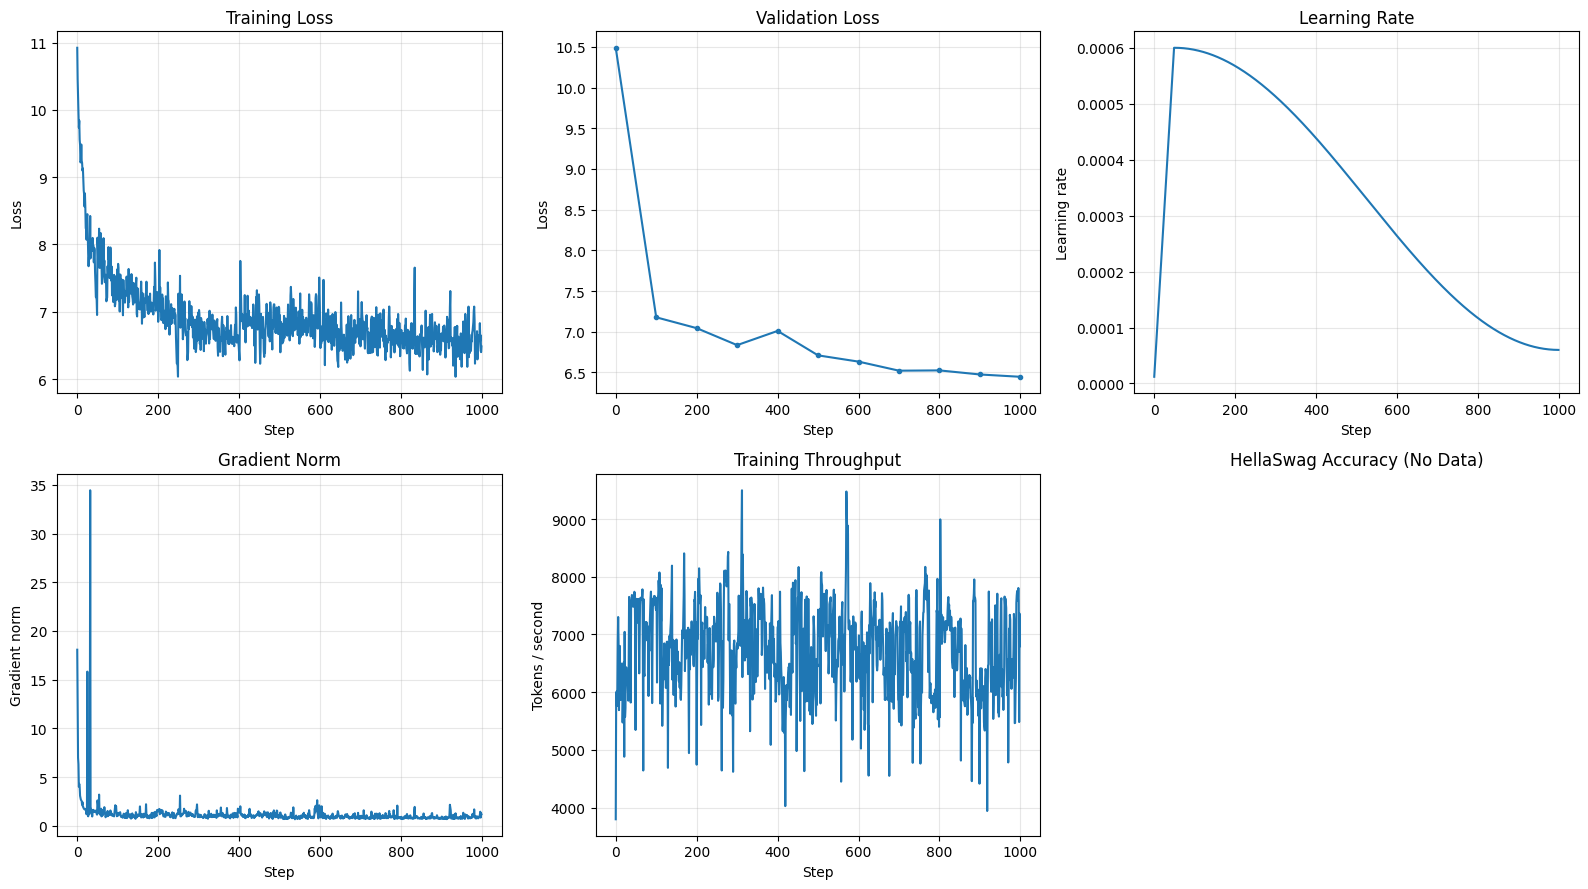

Individual training graphs saved to: /DATA/tt/DumGPT/outputs/plots

--- Sample Generation ---
The history of artificial intelligence begins with a two factors.
The American study of an risk of the other health of the first years was not to the use or to the child. The first, a second-scale and has been in which was a problem.
to-level and the first than it was to identify their body had


In [14]:
create_training_graphs(OUTPUT_DIR / "metrics.csv", OUTPUT_DIR / "plots")

@torch.no_grad()
def generate_text(prompt: str, max_new_tokens: int = 60, top_k: int = 50, temperature: float = 0.8):
    model.eval()
    tokens = enc.encode(prompt)
    xgen = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new_tokens):
        logits, _ = model(xgen[:, -BLOCK_SIZE:])
        logits = logits[:, -1, :] / max(temperature, 1e-5)
        probs = F.softmax(logits, dim=-1)
        topk_prob, topk_idx = torch.topk(probs, k=top_k, dim=-1)
        next_token = topk_idx.gather(-1, torch.multinomial(topk_prob, num_samples=1))
        xgen = torch.cat((xgen, next_token), dim=1)
    return enc.decode(xgen[0].tolist())

print("\n--- Sample Generation ---")
print(generate_text("The history of artificial intelligence begins with", max_new_tokens=60))


## Step 12: Optional Hugging Face export

This cell is optional. It is disabled by default so the notebook can run fully locally without authentication or uploading files.
Set `ENABLE_HF_UPLOAD = True` and enter a Hugging Face write token when you intentionally want to publish the model.


In [16]:
import json 
# OPTIONAL: Upload model weights, metrics, plots, and resumable checkpoint to Hugging Face.
ENABLE_HF_UPLOAD = True

if ENABLE_HF_UPLOAD:
    from huggingface_hub import HfApi, create_repo, login
    import getpass

    HF_REPO_ID = "shubhamisok/DumGPT-124M"
    PRIVATE_REPO = False

    hf_token = os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face write token: ")
    login(token=hf_token)

    EXPORT_DIR = BASE_DIR / "hf_export"
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)

    torch.save(model.state_dict(), EXPORT_DIR / "pytorch_model.bin")
    with (EXPORT_DIR / "config.json").open("w", encoding="utf-8") as f:
        json.dump(config.__dict__, f, indent=2)

    model_card = f"""---
language: en
license: mit
datasets:
- HuggingFaceFW/fineweb-edu
tags:
- gpt2
- pytorch
- pretraining
---

# DumGPT (GPT-2 124M)

A GPT-2-style 124M parameter model trained from scratch.

- Layers: {config.n_layer}
- Heads: {config.n_head}
- Embedding dimension: {config.n_embd}
- Context length: {config.block_size}
- Vocabulary size: {config.vocab_size}
"""
    (EXPORT_DIR / "README.md").write_text(model_card, encoding="utf-8")

    api = HfApi()
    create_repo(repo_id=HF_REPO_ID, repo_type="model", private=PRIVATE_REPO, exist_ok=True)
    api.upload_folder(
        folder_path=str(EXPORT_DIR),
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message="Upload DumGPT model weights and config",
    )

    if latest_ckpt.exists():
        api.upload_file(
            path_or_fileobj=str(latest_ckpt),
            path_in_repo="checkpoints/latest.pt",
            repo_id=HF_REPO_ID,
            repo_type="model",
            commit_message="Upload resumable training checkpoint",
        )
    if OUTPUT_DIR.exists():
        api.upload_folder(
            folder_path=str(OUTPUT_DIR),
            path_in_repo="outputs",
            repo_id=HF_REPO_ID,
            repo_type="model",
            commit_message="Upload training logs and plots",
        )
    print(f"Uploaded: https://huggingface.co/{HF_REPO_ID}")
else:
    print("HF upload disabled. Your model and outputs remain local.")


Hugging Face write token:  ········


Processing Files (0 / 0): |                                                                |  0.00B /  0.00B            
Processing Files (0 / 1):  33%|███████████████████▊                                        |  492MB / 1.49GB, 41.5MB/s  
Processing Files (0 / 1):  33%|███████████████████▊                                        |  493MB / 1.49GB, 38.6MB/s  
Processing Files (0 / 1):  33%|███████████████████▊                                        |  493MB / 1.49GB, 36.3MB/s  
Processing Files (0 / 1):  33%|███████████████████▊                                        |  494MB / 1.49GB, 32.7MB/s  
Processing Files (0 / 1):  33%|███████████████████▊                                        |  495MB / 1.49GB, 32.2MB/s  
Processing Files (0 / 1):  33%|███████████████████▉                                        |  495MB / 1.49GB, 31.4MB/s  
Processing Files (0 / 1):  33%|███████████████████▉                                        |  496MB / 1.49GB, 30.9MB/s  
Processing Files (0 / 1):  33%|█

Uploaded: https://huggingface.co/shubhamisok/DumGPT-124M
